In [2]:
import cv2
import matplotlib.pyplot as plt
import math
import numpy as np
from PIL import Image

In [3]:
def upscale_bilinear_vectorized(image,scale):
    height,width = image.shape
    outHeight,outWidth = height*scale,width*scale

    rows = np.arange(outHeight,dtype=np.float32 )
    cols = np.arange(outWidth,dtype=np.float32 )

    x = (cols + 0.5) / scale - 0.5
    y = (rows + 0.5) / scale - 0.5

    X,Y = np.meshgrid(x,y)  # creates a vectorized array all at once, no for loops (does the calculations at once parrallely)

    # 2. Compute floor indices and fractional weights vectorially
    x0 = np.floor(X).astype(np.int32)
    y0 = np.floor(Y).astype(np.int32)

    # Safely clamp upper and lower bounds to prevent index errors
    x1 = np.clip(x0+1,0,width-1)
    y1 = np.clip(y0+1,0,height-1)
    x0 = np.clip(x0,0,width-1)
    y0 = np.clip(y0,0,height-1)

    tx = X - x0
    ty = Y - y0

    # 3. Vectorized neighbor gathering using advanced indexing
    Ia = image[y0, x0]
    Ib = image[y0, x1]
    Ic = image[y1, x0]
    Id = image[y1, x1]
    
    # 4. Vectorized Bilinear Interpolation formula (executed across all pixels at once)
    top = Ia * (1.0 - tx) + Ib * tx
    bottom = Ic * (1.0 - tx) + Id * tx
    output = top * (1.0 - ty) + bottom * ty

    return output
    

In [4]:
def downsample_2x(image):
    h, w = image.shape
    
    # Reshape the 2D image into 4D blocks of (h//2, 2, w//2, 2)
    # and average over the block axes (1 and 3)
    return image.reshape(h // 2, 2, w // 2, 2).mean(axis=(1, 3)).astype(image.dtype)

In [14]:
def calculate_mse(original, reconstructed):
    """
    Computes Mean Squared Error (MSE) for grayscale or RGB images.
    Automatically handles 2D (H, W) or 3D (H, W, C) arrays.
    """
    if original.shape != reconstructed.shape:
        raise ValueError(f"Shape mismatch: {original.shape} vs {reconstructed.shape}")
    
    # Cast to float64 to prevent uint8 underflow/overflow issues during subtraction
    orig_f = original.astype(np.float64)
    recon_f = reconstructed.astype(np.float64)
    
    # Vectorized calculation over all elements
    return float(np.mean((orig_f - recon_f) ** 2))

def calculate_psnr(original, reconstructed, max_val=255.0):
    """
    Computes Peak Signal-to-Noise Ratio (PSNR) in decibels (dB).
    Returns infinity if images are pixel-for-pixel identical.
    """
    mse = calculate_mse(original, reconstructed)
    
    if mse == 0:
        return float('inf')
    
    return float(10 * np.log10((max_val ** 2) / mse))


import numpy as np
from scipy.ndimage import uniform_filter

def image_stats(img, window_size=11):
    img = np.asarray(img, dtype=np.float64)

    mean = uniform_filter(img, size=window_size)
    variance = uniform_filter(
        img ** 2, size=window_size
    ) - mean ** 2

    return mean, np.maximum(variance, 0)


def calculate_covariance(A, B, window_size=11):
    A = np.asarray(A, dtype=np.float64)
    B = np.asarray(B, dtype=np.float64)

    mean_A = uniform_filter(A, size=window_size)
    mean_B = uniform_filter(B, size=window_size)

    mean_AB = uniform_filter(
        A * B, size=window_size
    )

    return mean_AB - mean_A * mean_B


# 1. Local SSIM — returns the full SSIM map
def calculate_local_ssim(A, B, window_size=11):
    A = np.asarray(A, dtype=np.float64)
    B = np.asarray(B, dtype=np.float64)

    if A.shape != B.shape or A.ndim != 2:
        raise ValueError("Expected matching 2D images")

    mean_A, var_A = image_stats(A, window_size)
    mean_B, var_B = image_stats(B, window_size)

    cov = calculate_covariance(A, B, window_size)

    C1 = (0.01 * 255) ** 2
    C2 = (0.03 * 255) ** 2

    L = (2 * mean_A * mean_B + C1) / (
        mean_A ** 2 + mean_B ** 2 + C1
    )

    CS = (2 * cov + C2) / (
        var_A + var_B + C2
    )

    return L * CS


# 2. SSIM — returns the overall mean SSIM score
def calculate_ssim(A, B, window_size=11):
    ssim_map = calculate_local_ssim(
        A, B, window_size
    )

    return float(np.mean(ssim_map))


# RGB SSIM: SSIM is defined on 2D images, so run it on each channel separately.
# (Passing (H, W, 3) straight into uniform_filter would also average across the
# channel axis and mix R, G and B together.)
def calculate_ssim_rgb(original, reconstructed, window_size=11):
    original = np.asarray(original, dtype=np.float64)
    reconstructed = np.asarray(reconstructed, dtype=np.float64)

    if original.shape != reconstructed.shape or original.ndim != 3 or original.shape[2] != 3:
        raise ValueError(f"Expected matching (H, W, 3) images, got {original.shape} and {reconstructed.shape}")

    # Each channel is its own 2D image -> reuse the grayscale SSIM
    per_channel = [
        calculate_ssim(original[:, :, k], reconstructed[:, :, k], window_size)
        for k in range(3)
    ]
    ssim_r, ssim_g, ssim_b = per_channel

    return ssim_r, ssim_g, ssim_b, float(np.mean(per_channel))


def calculate_local_ssim_rgb(original, reconstructed, window_size=11):
    original = np.asarray(original, dtype=np.float64)
    reconstructed = np.asarray(reconstructed, dtype=np.float64)

    if original.shape != reconstructed.shape or original.ndim != 3 or original.shape[2] != 3:
        raise ValueError(f"Expected matching (H, W, 3) images, got {original.shape} and {reconstructed.shape}")

    # One (H, W) SSIM map per channel, stacked back to (H, W, 3)
    maps = [
        calculate_local_ssim(original[:, :, k], reconstructed[:, :, k], window_size)
        for k in range(3)
    ]
    return np.stack(maps, axis=-1)

import numpy as np

def calculate_mse_rgb(original, reconstructed):
    # 1. Validate image dimensions match
    if original.shape != reconstructed.shape:
        raise ValueError(f"Shape mismatch: original {original.shape} vs reconstructed {reconstructed.shape}")
    
    # Cast to float to prevent integer overflow/underflow issues with uint8
    orig_f = original.astype(np.float64)
    recon_f = reconstructed.astype(np.float64)
    
    # 2. Calculate squared differences across all dimensions: shape (H, W, 3)
    diff_sq = (orig_f - recon_f) ** 2
    
    # 3. Calculate MSE for each individual channel (averaging over height and width)
    mse_r = np.mean(diff_sq[:, :, 0])
    mse_g = np.mean(diff_sq[:, :, 1])
    mse_b = np.mean(diff_sq[:, :, 2])
    
    # 4. Calculate total RGB MSE (averaging over H, W, and channels all at once)
    mse_total = np.mean(diff_sq)
    
    return mse_r, mse_g, mse_b, mse_total


import numpy as np

def calculate_psnr_rgb(original, reconstructed, max_val=255.0):
    # Get MSE values using your previous function
    mse_r, mse_g, mse_b, mse_total = calculate_mse_rgb(original, reconstructed)
    
    # Handle zero MSE (identical images) to avoid division by zero / log(0)
    if mse_total == 0:
        return float('inf')
    
    # Calculate overall RGB PSNR
    psnr = 10 * np.log10((max_val ** 2) / mse_total)
    psnr_r = 10 * np.log10((max_val ** 2) / mse_r)
    psnr_g = 10 * np.log10((max_val ** 2) / mse_g)
    psnr_b = 10 * np.log10((max_val ** 2) / mse_b)
    
    return float(psnr),float(psnr_r),float(psnr_g),float(psnr_b)

from numpy.lib.stride_tricks import sliding_window_view


def calculate_local_ssim_optimized(A, B, window_size=3,
                                   C1=(0.01 * 255) ** 2, C2=(0.03 * 255) ** 2):
    # float64 first: uint8 math overflows (same bug we hit in the loop version)
    A = np.asarray(A, dtype=np.float64)
    B = np.asarray(B, dtype=np.float64)
    if A.shape != B.shape:
        raise ValueError("A and B must have the same shape")

    def window_mean(X):
        # view of shape (out_h, out_w, window, window), no copy;
        # each X[i, j] is the window starting at (i, j) -> average it
        windows = sliding_window_view(X, (window_size, window_size))
        return windows.mean(axis=(-2, -1))

    mu_a = window_mean(A)
    mu_b = window_mean(B)

    # same maths as image_stats / calculate_covariance (divide by N):
    #   variance   = mean(x^2) - mean(x)^2
    #   covariance = mean(x*y) - mean(x) * mean(y)
    sigma_a_sq = window_mean(A * A) - mu_a ** 2
    sigma_b_sq = window_mean(B * B) - mu_b ** 2
    sigma_ab = window_mean(A * B) - mu_a * mu_b

    numerator = (2 * mu_a * mu_b + C1) * (2 * sigma_ab + C2)
    denominator = (mu_a ** 2 + mu_b ** 2 + C1) * (sigma_a_sq + sigma_b_sq + C2)

    return numerator / denominator

In [6]:
import numpy as np

def upscale_bilinear_rgb_vectorized(image, scale):
    height, width, channels = image.shape
    out_height = int(height * scale)
    out_width = int(width * scale)

    # 1. Create coordinate grids for the entire output image at once
    rows = np.arange(out_height, dtype=np.float32)
    cols = np.arange(out_width, dtype=np.float32)
    col_grid, row_grid = np.meshgrid(cols, rows)

    # Map output coordinates to input coordinates
    x = (col_grid + 0.5) / scale - 0.5
    y = (row_grid + 0.5) / scale - 0.5

    # 2. Find integer neighbor coordinates with clipping to stay in bounds
    x0 = np.floor(x).astype(np.int32)
    y0 = np.floor(y).astype(np.int32)
    x1 = np.clip(x0 + 1, 0, width - 1)
    y1 = np.clip(y0 + 1, 0, height - 1)
    x0 = np.clip(x0, 0, width - 1)
    y0 = np.clip(y0, 0, height - 1)

    # Fractional weights for interpolation (add channel axis for broadcasting)
    tx = (x - x0)[..., np.newaxis]
    ty = (y - y0)[..., np.newaxis]

    # 3. Extract four neighbor matrices from the image array
    a = image[y0, x0]  # Top-Left
    b = image[y0, x1]  # Top-Right
    c = image[y1, x0]  # Bottom-Left
    d = image[y1, x1]  # Bottom-Right

    # 4. Vectorized Bilinear Interpolation across all channels simultaneously
    l1 = a + tx * (b - a)
    l2 = c + tx * (d - c)
    output = l1 + ty * (l2 - l1)

    # 5. Clip and cast back to uint8 if input was an image
    output = np.clip(output, 0, 255).astype(np.uint8)

    return output

In [7]:
def downsample_rgb_vectorized(image):
    h, w, c = image.shape
    # Reshape into blocks of (h//2, 2, w//2, 2, c) and average over the block axes (1 and 3)
    return image.reshape(h // 2, 2, w // 2, 2, c).mean(axis=(1, 3)).astype(np.float64)

## Real grayscale video reconstruction


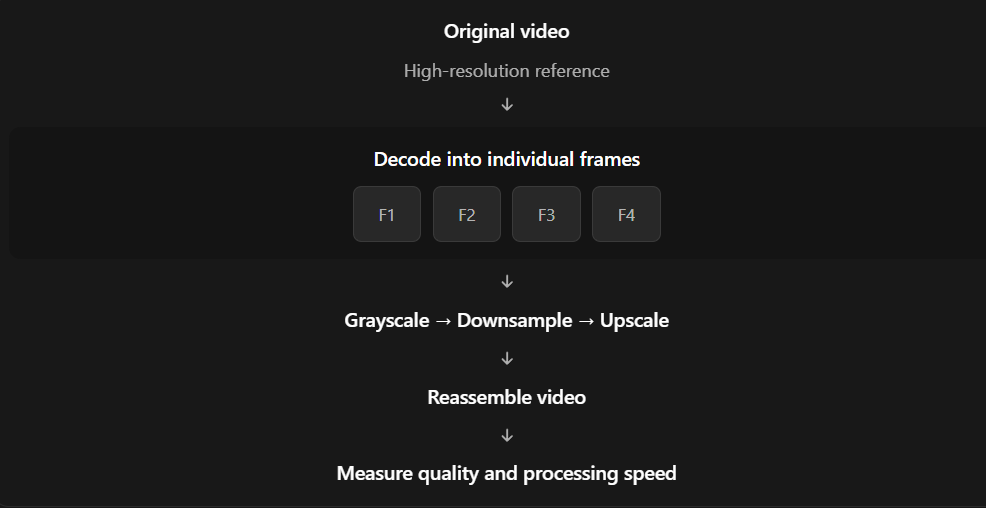

Extraction

FPS: 29.5
Frames: 564.0
Frame shape: (608, 1080)


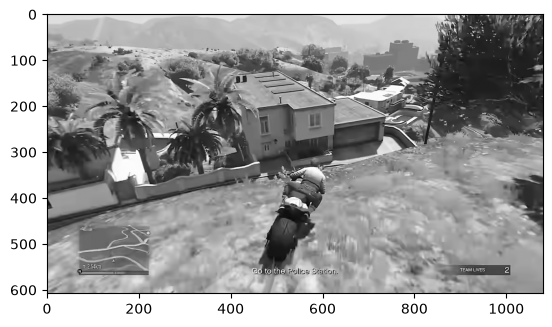

In [8]:
import cv2
import matplotlib.pyplot as plt

video = cv2.VideoCapture("ginue-pigs/gta5.mp4")

fps = video.get(cv2.CAP_PROP_FPS)
frame_count = video.get(cv2.CAP_PROP_FRAME_COUNT)

success, frame = video.read()

if not success:
    raise ValueError("Could not read video")

gray = cv2.cvtColor(
    frame, cv2.COLOR_BGR2GRAY
)

print("FPS:", fps)
print("Frames:", frame_count)
print("Frame shape:", gray.shape)

plt.imshow(gray, cmap="gray")
plt.show()

video.release()

In [9]:
downSample = downsample_2x(gray)
reconstructed = upscale_bilinear_vectorized(downSample,2)

In [ ]:
# cv2.imwrite("gray.png", gray)
# cv2.imwrite("reconstructed.png", reconstructed)

True

## Lets check out how much wrong we were

In [12]:
print("MSE: ",calculate_mse(gray,reconstructed))
print("PSNR: ",calculate_psnr(gray,reconstructed))
print("SSIM: ",calculate_ssim(gray,reconstructed))

MSE:  109.46953755577637
PSNR:  27.737870774177345
SSIM:  0.9426963559602928


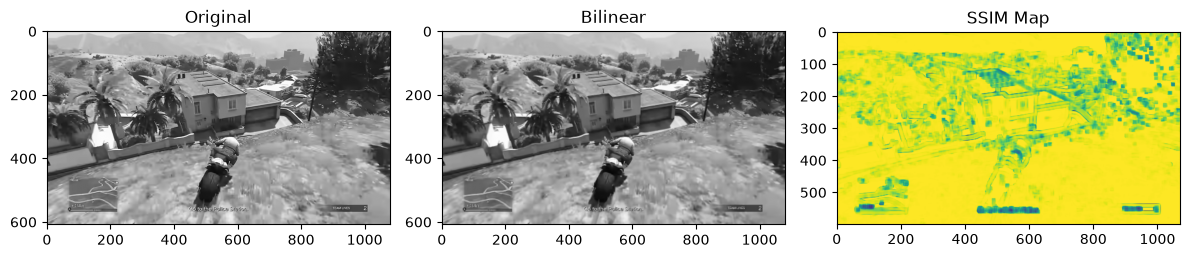

In [15]:
ssim_map = calculate_local_ssim_optimized(
    gray,
    reconstructed,
    11
)

fig,axes = plt.subplots(1,3,figsize = (12,4))

axes[0].imshow(gray,cmap="gray")
axes[0].set_title("Original")

axes[1].imshow(reconstructed, cmap="gray")
axes[1].set_title("Bilinear")

axes[2].imshow(
    ssim_map,
    cmap="viridis",
    vmin=0,
    vmax=1
)
axes[2].set_title("SSIM Map")

plt.tight_layout()
plt.show()



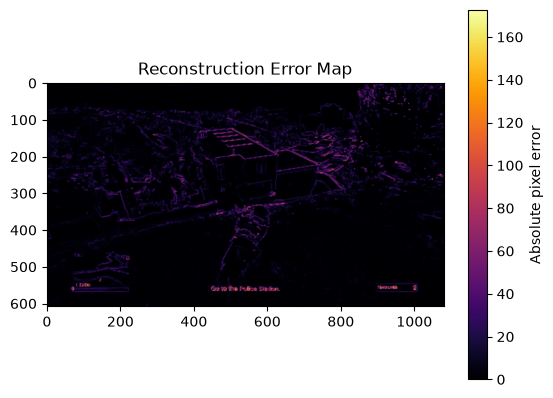

In [16]:
error_map = np.abs(
    gray.astype(float)
    - reconstructed.astype(float)
)

plt.imshow(error_map, cmap="inferno")
plt.colorbar(label="Absolute pixel error")
plt.title("Reconstruction Error Map")
plt.show()

### Lets try this on 1-second of video

In [25]:
import cv2
import time
import numpy as np

video = cv2.VideoCapture("ginue-pigs/gta5.mp4")

mse_scores = []
psnr_scores = []
ssim_scores = []
processing_times = []

for i in range(30):
    success, frame = video.read()

    if not success:
        break

    gray = cv2.cvtColor(
        frame, cv2.COLOR_BGR2GRAY
    ).astype(np.float64)

    start = time.perf_counter()

    # 1. Downsample gray by 2x
    down = downsample_2x(gray)

    # 2. Reconstruct using bilinear
    recon = upscale_bilinear_vectorized(down,2)

    # 3. Calculate MSE, PSNR, SSIM
    mse = calculate_mse(gray,recon)
    psnr = calculate_psnr(gray,recon)
    ssim = calculate_local_ssim_optimized(gray,recon)

    # 4. Append results to their lists
    mse_scores.append(mse)
    psnr_scores.append(psnr)
    ssim_scores.append(ssim)

    elapsed = time.perf_counter() - start
    processing_times.append(elapsed)

video.release()

In [28]:
avg_mse = np.mean(mse_scores)
avg_psnr = np.mean(psnr_scores)
avg_ssim = np.mean(ssim_scores)
avg_time = np.mean(processing_times)

In [29]:
print(avg_mse)
print(avg_psnr)
print(avg_ssim)
print(avg_time)

86.548242652551
28.79376854398038
0.9340240318568229
0.2692349366666728


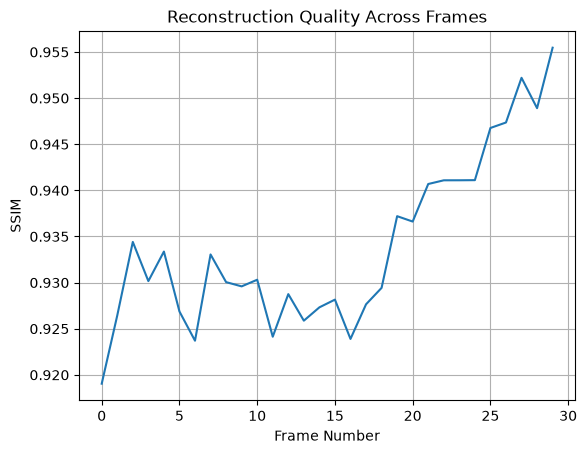

In [32]:
frame_ssim_scores = [
    np.mean(ssim_map)
    for ssim_map in ssim_scores
]

plt.plot(frame_ssim_scores)
plt.xlabel("Frame Number")
plt.ylabel("SSIM")
plt.title("Reconstruction Quality Across Frames")
plt.grid(True)
plt.show()

In [34]:
print("Average SSIM:", np.mean(frame_ssim_scores))
print("Min SSIM:", np.min(frame_ssim_scores))
print("Max SSIM:", np.max(frame_ssim_scores))

print("Worst frame:", np.argmin(frame_ssim_scores))
print("Best frame:", np.argmax(frame_ssim_scores))

Average SSIM: 0.9340240318568226
Min SSIM: 0.919042211922671
Max SSIM: 0.9554662025856601
Worst frame: 0
Best frame: 29


## Alright, lets get to it. Finally we will upscale the shit out of our video

In [36]:
import cv2
import numpy as np

video = cv2.VideoCapture("ginue-pigs/gta5.mp4")

fps = video.get(cv2.CAP_PROP_FPS)

width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    "reconstructed_gray.mp4",
    fourcc,
    fps,
    (width, height)
)

if not video.isOpened() or not writer.isOpened():
    raise RuntimeError("Video input or output failed")

while True:
    success, frame = video.read()

    if not success:
        break

    gray = cv2.cvtColor(
        frame, cv2.COLOR_BGR2GRAY
    ).astype(np.float64)

    # 1. Downsample by 2x
    down = downsample_2x(gray)

    # 2. Upscale using bilinear interpolation
    recon = upscale_bilinear_vectorized(down,2)

    # 3. Convert result to uint8
    recon = np.clip(recon,0,255).astype(np.uint8)

    # 4. Convert grayscale output to BGR
    #    (VideoWriter expects 3-channel frames here)

    recon_bgr = cv2.cvtColor(
        recon, cv2.COLOR_GRAY2BGR
    )

    # 5. Write reconstructed frame
    writer.write(recon_bgr)

video.release()
writer.release()

In [37]:
output = cv2.VideoCapture("reconstructed_gray.mp4")

print("Opened:", output.isOpened())
print("FPS:", output.get(cv2.CAP_PROP_FPS))
print("Frames:", output.get(cv2.CAP_PROP_FRAME_COUNT))

success, frame = output.read()
print("First frame readable:", success)

output.release()

Opened: True
FPS: 29.5
Frames: 564.0
First frame readable: True


## RGB conversion

In [ ]:
video = cv2.VideoCapture("ginue-pigs/gta5.mp4")

fps = video.get(cv2.CAP_PROP_FPS)

width = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))

fourcc = cv2.VideoWriter_fourcc(*"mp4v")

writer = cv2.VideoWriter(
    "reconstructed_gta5_rgb.mp4",
    fourcc,
    fps,
    (width, height)
)

if not video.isOpened():
    raise RuntimeError("Cannot open input video")

if not writer.isOpened():
    raise RuntimeError("Cannot create output video")

while True:
    assert recon_bgr.shape == (height, width, 3)
    success, frame = video.read()

    if not success:
        break

    # 1. Convert frame to float64
    frame = frame.astype(np.float64)

    # 2. Downsample the color frame
    down = downsample_rgb_vectorized(frame)

    # 3. Upscale the color frame
    recon = upscale_bilinear_rgb_vectorized(down,2)

    # 4. Convert to uint8
    recon_bgr = np.clip(recon,0,255).astype(np.uint8)

    # 5. Write the frame directly
    writer.write(recon_bgr)

video.release()
writer.release()

In [39]:
output = cv2.VideoCapture(
    "reconstructed_gta5_rgb.mp4"
)

print("Opened:", output.isOpened())
print("FPS:", output.get(cv2.CAP_PROP_FPS))
print("Frames:", output.get(cv2.CAP_PROP_FRAME_COUNT))

success, frame = output.read()
print("Readable:", success)

output.release()

Opened: True
FPS: 29.5
Frames: 564.0
Readable: True


In [40]:
start = time.perf_counter()

down = downsample_rgb_vectorized(frame)
recon = upscale_bilinear_rgb_vectorized(down, 2)

elapsed = time.perf_counter() - start
processing_times.append(elapsed)

In [41]:
total_time = sum(processing_times)

processing_fps = (
    len(processing_times) / total_time
)

print("Processing FPS:", processing_fps)
print("Average ms/frame:", np.mean(processing_times) * 1000)

Processing FPS: 3.742318709768271
Average ms/frame: 267.2140129032253


In [43]:
import cv2
import numpy as np
import time
import matplotlib.pyplot as plt

video = cv2.VideoCapture("ginue-pigs/gta5.mp4")

if not video.isOpened():
    raise RuntimeError("Could not open video")

mse_scores = []
psnr_scores = []
ssim_scores = []
processing_times = []

for i in range(30):
    success, frame = video.read()

    if not success:
        break

    original = frame.astype(np.float64)

    # Measure reconstruction time only
    start = time.perf_counter()

    down = downsample_rgb_vectorized(original)
    recon = upscale_bilinear_rgb_vectorized(down, 2)

    elapsed = time.perf_counter() - start
    processing_times.append(elapsed)

    if original.shape != recon.shape:
        raise ValueError("Frame dimensions do not match")

    # MSE
    mse_r, mse_g, mse_b, mse_total = calculate_mse_rgb(
        original, recon
    )

    # PSNR from overall RGB MSE
    psnr = (
        float("inf") if mse_total == 0
        else 10 * np.log10(255**2 / mse_total)
    )

    # SSIM
    ssim_r, ssim_g, ssim_b, ssim_total = calculate_ssim_rgb(
        original, recon
    )

    mse_scores.append(mse_total)
    psnr_scores.append(psnr)
    ssim_scores.append(ssim_total)

video.release()

In [44]:
avg_mse = np.mean(mse_scores)
avg_psnr = np.mean(psnr_scores)
avg_ssim = np.mean(ssim_scores)

avg_time = np.mean(processing_times) * 1000
processing_fps = len(processing_times) / sum(processing_times)

print("Frames:", len(mse_scores))

print("Average MSE:", avg_mse)
print("Average PSNR:", avg_psnr)
print("Average SSIM:", avg_ssim)

print("Min SSIM:", np.min(ssim_scores))
print("Max SSIM:", np.max(ssim_scores))

print("Average ms/frame:", avg_time)
print("Processing FPS:", processing_fps)

Frames: 30
Average MSE: 86.53896995817088
Average PSNR: 28.794626970349842
Average SSIM: 0.9555717270669002
Min SSIM: 0.9413934992377414
Max SSIM: 0.9699171415000037
Average ms/frame: 194.58361333324018
Processing FPS: 5.139178900370296


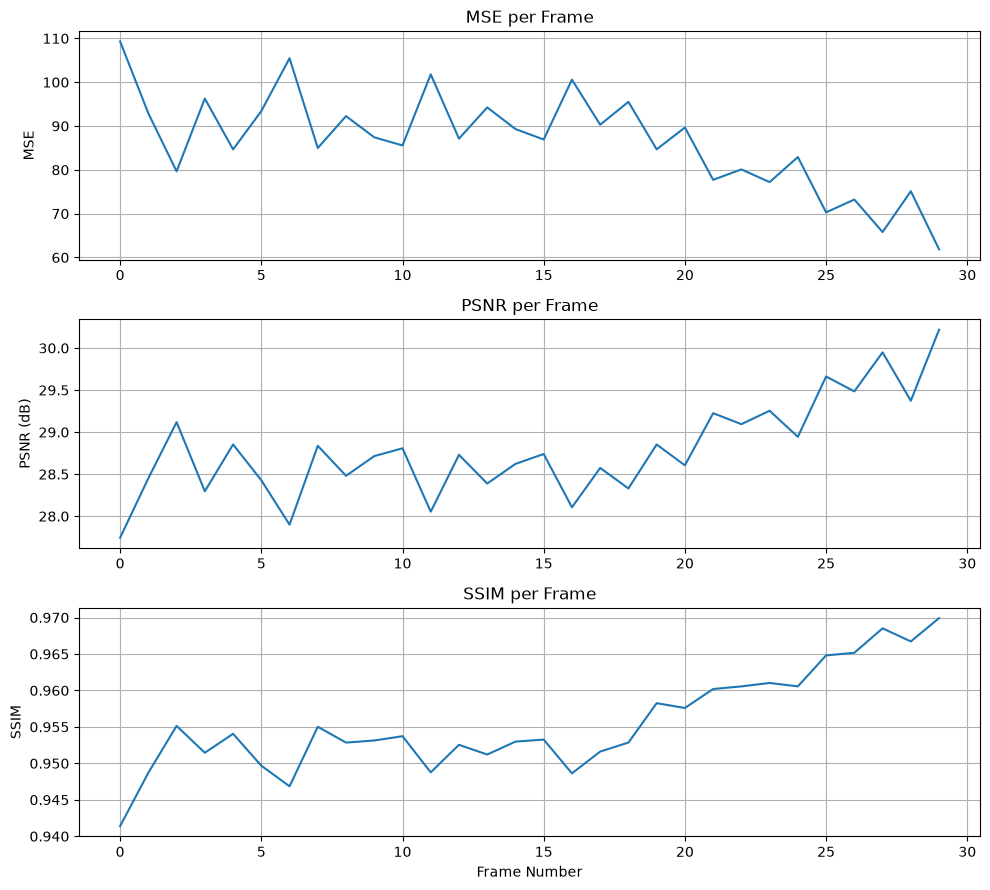

In [45]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9))

axes[0].plot(mse_scores)
axes[0].set_title("MSE per Frame")
axes[0].set_ylabel("MSE")

axes[1].plot(psnr_scores)
axes[1].set_title("PSNR per Frame")
axes[1].set_ylabel("PSNR (dB)")

axes[2].plot(ssim_scores)
axes[2].set_title("SSIM per Frame")
axes[2].set_ylabel("SSIM")
axes[2].set_xlabel("Frame Number")

for ax in axes:
    ax.grid(True)

plt.tight_layout()
plt.show()

In [46]:
video = cv2.VideoCapture("ginue-pigs/gta5.mp4")
success, frame = video.read()
video.release()

if success:
    b, g, r = cv2.split(
        frame.astype(np.float64)
    )

    print("B-G difference:", np.mean(np.abs(b-g)))
    print("G-R difference:", np.mean(np.abs(g-r)))
    print("R-B difference:", np.mean(np.abs(r-b)))

B-G difference: 28.645158686647175
G-R difference: 13.60250365497076
R-B difference: 40.55823434454191
